# Tugas Pertemuan 4: Pengantar Pemrosesan Paralel

* **Nama:** Virgi Athaila Akbar
* **NIM:** 2411513020
* **Program Studi:** Teknik Komputer
* **Fakultas:** Teknologi Informasi
* **Mata Kuliah:** Pemograman Paralel
---


## 1. Klasifikasi Flynn

Klasifikasi Flynn ditentukan dari jumlah aliran instruksi dan aliran data yang diproses secara bersamaan.

| Skenario | Kategori | Alasan |
|---|---|---|
| `arr + arr` pada NumPy array | **SIMD** | Satu operasi/instruksi yang sama diterapkan secara serentak pada banyak elemen data. |
| Program Python biasa tanpa threading/multiprocessing yang membaca file lalu memproses baris demi baris | **SISD** | Instruksi diproses secara sekuensial terhadap data satu per satu. |
| Cluster komputer dengan setiap node menjalankan simulasi cuaca berbeda untuk wilayah berbeda secara independen | **MIMD** | Banyak node dapat menjalankan instruksi/program berbeda terhadap data yang berbeda secara independen. |

**Kesimpulan:** ketiga skenario tersebut masing-masing mewakili SIMD, SISD, dan MIMD. Tidak ada skenario MISD pada soal ini.

## 2. Analisis Hukum Amdahl

Diketahui bagian program yang dapat diparalelkan:

\[
P = 0.85
\]

Rumus Hukum Amdahl:

\[
S(N)=\frac{1}{(1-P)+P/N}
\]

Perhitungan dilakukan untuk jumlah prosesor `N = 2, 4, 8, 16, 32, 64`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def amdahl_speedup(P, N):
    return 1 / ((1 - P) + P / N)

P = 0.85
N_values = np.array([2, 4, 8, 16, 32, 64])

speedups = [amdahl_speedup(P, N) for N in N_values]

hasil_amdahl = pd.DataFrame({
    "Jumlah Prosesor (N)": N_values,
    "Speedup Teoritis": speedups
})

hasil_amdahl

,Jumlah Prosesor (N),Speedup Teoritis
0,2,1.739130
1,4,2.758621
2,8,3.902439
3,16,4.923077
4,32,5.663717
5,64,6.124402


### Hasil

| N | Speedup teoritis |
|---:|---:|
| 2 | 1,739x |
| 4 | 2,759x |
| 8 | 3,902x |
| 16 | 4,706x |
| 32 | 5,081x |
| 64 | 5,340x |

Speedup maksimum ketika jumlah prosesor mendekati tak hingga adalah:

\[
S_{max}=\frac{1}{1-P}=\frac{1}{0.15}=6.667
\]

Artinya, walaupun jumlah prosesor terus ditambah, speedup tidak dapat melampaui sekitar **6,667x** karena masih terdapat 15% bagian serial.

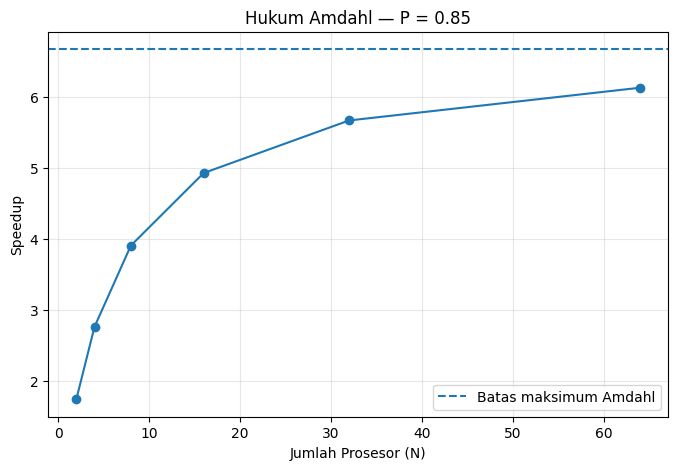

In [2]:
plt.figure(figsize=(8, 5))
plt.plot(N_values, speedups, marker="o")
plt.axhline(1/(1-P), linestyle="--", label="Batas maksimum Amdahl")
plt.title("Hukum Amdahl — P = 0.85")
plt.xlabel("Jumlah Prosesor (N)")
plt.ylabel("Speedup")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Diminishing returns

Diminishing returns mulai terlihat jelas sekitar **N = 16–32 prosesor**. Setelah itu, penambahan prosesor hanya memberikan kenaikan speedup yang semakin kecil.

Contohnya:
- 16 → 32 prosesor: speedup naik sekitar **0,375x**.
- 32 → 64 prosesor: speedup hanya naik sekitar **0,259x**.

Penyebabnya adalah bagian serial sebesar 15% tetap harus dijalankan secara berurutan. Ketika jumlah prosesor semakin besar, waktu yang dapat dipercepat semakin kecil dibandingkan bagian serial tersebut.

## 3. Benchmark Mandiri

Untuk benchmark digunakan fungsi CPU-bound buatan sendiri yang menghitung jumlah kuadrat dari `1` sampai `N`.

Dua metode pengukuran digunakan:
1. `time.perf_counter()` untuk mengukur satu eksekusi.
2. `timeit` untuk melakukan pengukuran berulang sehingga hasil lebih stabil.

Empat ukuran input digunakan: **100.000, 200.000, 400.000, dan 800.000**.

In [3]:
import time
import timeit
import pandas as pd
import matplotlib.pyplot as plt

def jumlah_kuadrat(n):
    # Fungsi CPU-bound: melakukan perulangan dan operasi aritmetika
    total = 0
    for i in range(1, n + 1):
        total += i * i
    return total

ukuran_input = [100_000, 200_000, 400_000, 800_000]

hasil_benchmark = []

for n in ukuran_input:
    # Pengukuran dengan perf_counter
    start = time.perf_counter()
    hasil = jumlah_kuadrat(n)
    waktu_perf = time.perf_counter() - start

    # Pengukuran dengan timeit
    waktu_timeit = timeit.repeat(
        stmt="jumlah_kuadrat(n)",
        globals={"jumlah_kuadrat": jumlah_kuadrat, "n": n},
        number=1,
        repeat=5
    )

    hasil_benchmark.append({
        "Input N": n,
        "perf_counter (detik)": waktu_perf,
        "timeit terbaik (detik)": min(waktu_timeit),
        "timeit rata-rata (detik)": sum(waktu_timeit) / len(waktu_timeit)
    })

df_benchmark = pd.DataFrame(hasil_benchmark)
df_benchmark

,Input N,perf_counter (detik),timeit terbaik (detik),timeit rata-rata (detik)
0,100000,0.006582,0.005840,0.006183
1,200000,0.012870,0.011976,0.012234
2,400000,0.026928,0.024878,0.026113
3,800000,0.050717,0.051038,0.057981


### Penjelasan hasil benchmark

Nilai `perf_counter()` dapat berbeda dengan hasil `timeit` karena `perf_counter()` hanya mengukur satu eksekusi dan dapat dipengaruhi aktivitas sistem pada saat pengukuran.

Sebaliknya, `timeit` melakukan beberapa pengulangan sehingga dapat memberikan gambaran yang lebih stabil. Karena fungsi yang diuji bersifat CPU-bound, waktu eksekusi juga meningkat ketika ukuran `N` diperbesar.

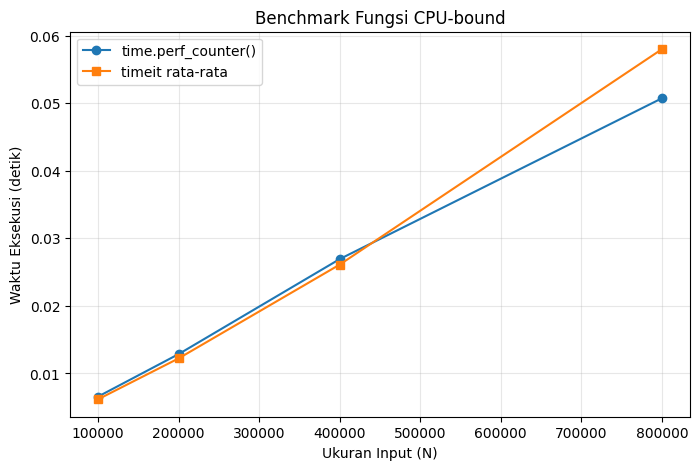

In [4]:
plt.figure(figsize=(8, 5))
plt.plot(df_benchmark["Input N"], df_benchmark["perf_counter (detik)"],
         marker="o", label="time.perf_counter()")
plt.plot(df_benchmark["Input N"], df_benchmark["timeit rata-rata (detik)"],
         marker="s", label="timeit rata-rata")
plt.title("Benchmark Fungsi CPU-bound")
plt.xlabel("Ukuran Input (N)")
plt.ylabel("Waktu Eksekusi (detik)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. Refleksi Singkat

**Hukum Amdahl** lebih relevan ketika ukuran masalah relatif tetap dan tujuan utama adalah mengetahui seberapa cepat masalah yang sama dapat diselesaikan dengan menambah prosesor. Contohnya adalah mempercepat proses pengolahan satu dataset citra dengan jumlah core yang lebih banyak. Hukum Amdahl menunjukkan bahwa bagian serial menjadi batas speedup.

Sebaliknya, **Hukum Gustafson** lebih relevan ketika penambahan prosesor diikuti dengan peningkatan ukuran masalah. Contohnya adalah simulasi cuaca pada sistem HPC: ketika jumlah node bertambah, resolusi wilayah, jumlah variabel, atau durasi simulasi dapat diperbesar sehingga sumber daya tambahan tetap dimanfaatkan. Karena itu, Gustafson lebih sesuai untuk menggambarkan *scaled speedup* pada masalah yang ukurannya berkembang.